<a href="https://colab.research.google.com/github/bandi137/w12-trendfigyelo/blob/main/W12_trendfigyelo_rag.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W12 – Kutatási trendfigyelő RAG-gal

**Mit csinál a notebook:** letölti az arXiv egy kategóriájának absztraktjait havi bontásban, vektorokká alakítja őket,
kérdésekre forrásmegjelöléssel válaszol (RAG), és kimutatja a felfutó témákat.

**Indítás előtt (egyszer):**
1. *Runtime → Change runtime type → T4 GPU*
2. Bal oldalt a 🔑 *Secrets* fülön vegyél fel egy `GEMINI_API_KEY` nevű titkot (kulcs: https://aistudio.google.com/apikey), és kapcsold be a notebook-hozzáférést.
3. *Runtime → Run all*. Az első futás (letöltés + vektorizálás) kb. 15–25 perc, utána a Drive-ról töltődik minden.


## 1. Telepítés és beállítások

In [ ]:
!pip install -q arxiv sentence-transformers google-genai

In [ ]:
# --- Beállítások: itt lehet hangolni ---
CATEGORY   = "cs.CL"        # arXiv kategória
MONTHS     = 12             # hány hónapra visszamenőleg
PER_MONTH  = 400            # cikk / hónap (12 x 400 = 4800 absztrakt)
EMB_MODEL  = "intfloat/multilingual-e5-base"   # többnyelvű -> magyar kérdés is működik
LLM_MODEL  = "gemini-3.5-flash-lite"           # ha hibát ad, nézd meg az aktuális nevet az AI Studióban
TOP_K      = 5              # ennyi cikket kap meg a nyelvi modell
N_TOPICS   = 25             # témák száma a trendelemzéshez

from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = f"/content/drive/MyDrive/W12_trendfigyelo/{CATEGORY.replace('.', '_')}"
import os; os.makedirs(DATA_DIR, exist_ok=True)
print("Adatmappa:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Adatmappa: /content/drive/MyDrive/W12_trendfigyelo/cs_CL


## 2. Adatgyűjtés az arXivról (havonta `PER_MONTH` cikk, egyszer fut, utána a Drive-ról töltődik)

In [ ]:
import arxiv, pandas as pd, time
from datetime import date

def month_ranges(n):
    today = date.today().replace(day=1)
    out = []
    for i in range(n, 0, -1):
        y, m = today.year, today.month - i
        while m <= 0:
            m += 12; y -= 1
        ny, nm = (y + 1, 1) if m == 12 else (y, m + 1)
        out.append((f"{y}{m:02d}010000", f"{ny}{nm:02d}010000", f"{y}-{m:02d}"))
    return out

csv_path = f"{DATA_DIR}/papers.csv"
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path, dtype={"id": str})
    print("Betöltve a Drive-ról:", len(df), "cikk")
else:
    client = arxiv.Client(page_size=200, delay_seconds=3, num_retries=5)
    rows = []
    for start, end, label in month_ranges(MONTHS):
        search = arxiv.Search(query=f"cat:{CATEGORY} AND submittedDate:[{start} TO {end}]",
                              max_results=PER_MONTH,
                              sort_by=arxiv.SortCriterion.SubmittedDate)
        n0 = len(rows)
        for r in client.results(search):
            rows.append({"id": r.get_short_id().split("v")[0], "title": " ".join(r.title.split()),
                         "abstract": " ".join(r.summary.split()), "published": r.published.date().isoformat(),
                         "month": label, "authors": ", ".join(a.name for a in r.authors[:5]),
                         "url": r.entry_id})
        print(label, len(rows) - n0, "cikk")
    df = pd.DataFrame(rows).drop_duplicates("id").reset_index(drop=True)
    df.to_csv(csv_path, index=False)
    print("Mentve:", csv_path, len(df), "cikk")
df.head()

2025-11 400 cikk
2025-12 400 cikk
2026-01 400 cikk
2026-02 400 cikk
2026-03 400 cikk
2026-04 400 cikk
2026-05 400 cikk
2026-06 400 cikk
2026-07 400 cikk
2026-08 400 cikk
2026-09 400 cikk
2026-10 400 cikk
Mentve: /content/drive/MyDrive/W12_trendfigyelo/cs_CL/papers.csv 4800 cikk


,id,title,abstract,published,month,authors,url
0,2512.01127,Mode-Conditioning Unlocks Superior Test-Time S...,Parallel sampling promises substantial gains i...,2025-11-30,2025-11,"Chen Henry Wu, Sachin Goyal, Aditi Raghunathan",http://arxiv.org/abs/2512.01127v1
1,2512.01109,How do we measure privacy in text? A survey of...,"In this work, we aim to clarify and reconcile ...",2025-11-30,2025-11,"Yaxuan Ren, Krithika Ramesh, Yaxing Yao, Anjal...",http://arxiv.org/abs/2512.01109v1
2,2512.01085,Generalised Medical Phrase Grounding,Medical phrase grounding (MPG) maps textual de...,2025-11-30,2025-11,"Wenjun Zhang, Shekhar S. Chandra, Aaron Nicolson",http://arxiv.org/abs/2512.01085v3
3,2512.01081,Testing the Machine Consciousness Hypothesis,The Machine Consciousness Hypothesis states th...,2025-11-30,2025-11,Stephen Fitz,http://arxiv.org/abs/2512.01081v1
4,2512.01077,ELR-1000: A Community-Generated Dataset for En...,We present a culturally-grounded multimodal da...,2025-11-30,2025-11,"Neha Joshi, Pamir Gogoi, Aasim Mirza, Aayush J...",http://arxiv.org/abs/2512.01077v1


## 3. Vektorizálás (embedding) – egyszer fut, utána a Drive-ról töltődik

In [ ]:
import numpy as np
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(EMB_MODEL)
emb_path = f"{DATA_DIR}/embeddings.npy"
if os.path.exists(emb_path):
    emb = np.load(emb_path)
else:
    passages = ("passage: " + df.title + ". " + df.abstract).tolist()
    emb = model.encode(passages, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.save(emb_path, emb)
assert len(emb) == len(df), "A cikkek és a vektorok száma eltér – töröld az embeddings.npy-t és futtasd újra."

def embed_query(q):
    return model.encode(["query: " + q], normalize_embeddings=True)[0]
print(emb.shape)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/75 [00:00<?, ?it/s]

(4800, 768)


## 4. Visszakeresés és válaszgenerálás (RAG)

In [ ]:
def retrieve(question, k=TOP_K, month_from=None):
    """A kérdéshez legközelebbi k cikk (koszinusz-hasonlóság; a vektorok normáltak)."""
    scores = emb @ embed_query(question)
    if month_from:
        scores = np.where(df.month.values >= month_from, scores, -1)
    idx = np.argsort(-scores)[:k]
    hits = df.iloc[idx].copy()
    hits["score"] = scores[idx].round(3)
    return hits

PROMPT_TEMPLATE = """Kutatási asszisztens vagy. Kizárólag az alábbi arXiv-cikkek alapján válaszolj.
Minden állítás után tedd zárójelbe a forrás azonosítóját, pl. [2501.01234].
Ha a cikkekből nem derül ki a válasz, mondd meg őszintén. Válaszolj a kérdés nyelvén, legfeljebb 200 szóban.

CIKKEK:
{context}

KÉRDÉS: {question}
VÁLASZ:"""

def build_prompt(question, hits):
    context = "\n\n".join(f"[{r.id}] {r.title} ({r.month})\n{r.abstract}" for r in hits.itertuples())
    return PROMPT_TEMPLATE.format(context=context, question=question)

def check_citations(answer, hits):
    """Csak olyan azonosítóra hivatkozott-e, amit tényleg megkapott?"""
    import re
    cited = set(re.findall(r"\d{4}\.\d{4,5}", answer))
    return {"cited": sorted(cited), "invalid": sorted(cited - set(hits.id))}

In [ ]:
from google import genai
from google.colab import userdata
llm = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

log = []   # minden kérdés-válasz ide kerül -> dokumentációhoz
def ask(question, k=TOP_K, month_from=None, show=True):
    hits = retrieve(question, k, month_from)
    answer = llm.models.generate_content(model=LLM_MODEL, contents=build_prompt(question, hits)).text
    cit = check_citations(answer, hits)
    log.append({"question": question, "answer": answer, "sources": ", ".join(hits.id), **cit})
    if show:
        print(answer, "\n\nForrások:")
        for r in hits.itertuples():
            print(f"  [{r.id}] {r.score:.3f}  {r.title}")
        if cit["invalid"]:
            print("⚠ Nem kapott forrásra hivatkozott:", cit["invalid"])
    return answer

In [ ]:
ask("Milyen módszereket javasolnak mostanában a nagy nyelvi modellek hallucinációinak csökkentésére?")

A megadott cikkek alapján a következő módszereket javasolják a hallucinációk csökkentésére:

* **Hallucination Disentangled Decoding (HDD):** Egy tanítást nem igénylő módszer nagy vizuális-nyelvi modellekhez (LVLM), amely szegmentálja és kiegészíti a képet, valamint üres képet használ a nyelvi előítéletek kiküszöbölésére mind a nyelvi, mind a vizuális modalitásban [2512.19070].
* **NoLan (No-Language-Hallucination Decoding):** Egy egyszerű és tanítást nem igénylő keretrendszer, amely a nyelvi előítéletek dinamikus elnyomásával csökkenti a tárgyalapú hallucinációkat az LVLM-ekben [2602.22144].
* **SECRET (SourcE-Conditioned RElay sTeering):** Egy tanítást nem igénylő módszer audio-vizuális nagy nyelvi modellekhez (AVLLM), amely a kérdés-továbbítási ponton (question relay) kezeli a keresztmodalitású interferenciát és a szükséges forrásra irányítja a kérdésállapotokat [2609.37568].
* **Adatcentrikus stratégia és szegmensalapú visszakeresés:** A soknyelvű tudományos szövegekben történő hal

'A megadott cikkek alapján a következő módszereket javasolják a hallucinációk csökkentésére:\n\n* **Hallucination Disentangled Decoding (HDD):** Egy tanítást nem igénylő módszer nagy vizuális-nyelvi modellekhez (LVLM), amely szegmentálja és kiegészíti a képet, valamint üres képet használ a nyelvi előítéletek kiküszöbölésére mind a nyelvi, mind a vizuális modalitásban [2512.19070].\n* **NoLan (No-Language-Hallucination Decoding):** Egy egyszerű és tanítást nem igénylő keretrendszer, amely a nyelvi előítéletek dinamikus elnyomásával csökkenti a tárgyalapú hallucinációkat az LVLM-ekben [2602.22144].\n* **SECRET (SourcE-Conditioned RElay sTeering):** Egy tanítást nem igénylő módszer audio-vizuális nagy nyelvi modellekhez (AVLLM), amely a kérdés-továbbítási ponton (question relay) kezeli a keresztmodalitású interferenciát és a szükséges forrásra irányítja a kérdésállapotokat [2609.37568].\n* **Adatcentrikus stratégia és szegmensalapú visszakeresés:** A soknyelvű tudományos szövegekben törté

In [ ]:
ask("What are recent approaches to evaluating LLM agents?")

A legújabb kutatások során a nagyméretű nyelvi modell (LLM) ügynökök értékelésére számos specifikus megközelítést és benchmarksrendszert hoztak létre:

* **Vigilancia és befolyásolhatóság:** Az ügynökök éberségét (vigilance) három valósághű feladatban – veszélyes webhelyek navigálása, e-kereskedelmi csalások elkerülése és nem biztonságos kódrepositorik javítása – vizsgálták, feltárva a modell rosszindulatú befolyásokkal szembeni sérülékenységét [2601.21262].
* **Hosszú távú autonóm műveletek:** Az *AutoVend* benchmark egy olyan szimulált környezet, amelyben egy LLM ügynök 20 eladóautomatát kezel 180 napon keresztül, értékelve a webes alapú operációs felületen végzett koordinációt, a végrehajtást és a gazdasági megtérülést [2610.36980].
* **Nyílt világú feltárás:** A *MineExplorer* benchmark a Minecraftban vizsgálja a multimodális LLM ügynökök (MLLM) nyílt világú feltárási képességeit ReAct-stílusú feladatformulázással és többlépcsős atomi feladatokkal [2605.30931].
* **Erőforrás-helyre

'A legújabb kutatások során a nagyméretű nyelvi modell (LLM) ügynökök értékelésére számos specifikus megközelítést és benchmarksrendszert hoztak létre:\n\n* **Vigilancia és befolyásolhatóság:** Az ügynökök éberségét (vigilance) három valósághű feladatban – veszélyes webhelyek navigálása, e-kereskedelmi csalások elkerülése és nem biztonságos kódrepositorik javítása – vizsgálták, feltárva a modell rosszindulatú befolyásokkal szembeni sérülékenységét [2601.21262].\n* **Hosszú távú autonóm műveletek:** Az *AutoVend* benchmark egy olyan szimulált környezet, amelyben egy LLM ügynök 20 eladóautomatát kezel 180 napon keresztül, értékelve a webes alapú operációs felületen végzett koordinációt, a végrehajtást és a gazdasági megtérülést [2610.36980].\n* **Nyílt világú feltárás:** A *MineExplorer* benchmark a Minecraftban vizsgálja a multimodális LLM ügynökök (MLLM) nyílt világú feltárási képességeit ReAct-stílusú feladatformulázással és többlépcsős atomi feladatokkal [2605.30931].\n* **Erőforrás-

## 5. Trendelemzés: témák és havi részarányuk

In [ ]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

def find_topics(emb, texts, n_topics=N_TOPICS, seed=42):
    labels = KMeans(n_clusters=n_topics, n_init=10, random_state=seed).fit_predict(emb)
    # témánként összefűzött szöveg -> a témára jellemző kulcsszavak (class-based TF-IDF)
    docs = [" ".join(texts[labels == t]) for t in range(n_topics)]
    vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_df=0.5, min_df=1, sublinear_tf=True)
    X = vec.fit_transform(docs)
    terms = np.array(vec.get_feature_names_out())
    keywords = {t: ", ".join(terms[np.argsort(-X[t].toarray()[0])[:6]]) for t in range(n_topics)}
    return labels, keywords

def topic_trends(months, labels, window=3):
    """Havi részarány témánként + növekedés: utolsó `window` hónap átlaga / első `window` hónap átlaga."""
    share = pd.crosstab(months, labels, normalize="index").sort_index()
    first, last = share.iloc[:window].mean(), share.iloc[-window:].mean()
    growth = ((last + 0.005) / (first + 0.005)).sort_values(ascending=False)
    return share, growth

,kulcsszavak,cikkek,növekedés
topic,,,
4,"tajik, sealed, odrl, alarms, holdout, nb",290,9.25
1,"dim, sinks, sandbagging, midtraining, genpt, b...",224,3.56
16,"opd, opsd, distillation opd, student generated...",178,2.61
18,"deepresearch, effgen, gui agents, fortran, exe...",305,1.52
17,"decoding accelerates, drafter, decoding specul...",48,1.44
7,"personality traits, gender diversity, mandela,...",225,1.26
19,"agentic memory, locomo, mem, memory long, nati...",112,1.22
2,"jailbreaking, jailbreak, red teaming, untruste...",158,1.16


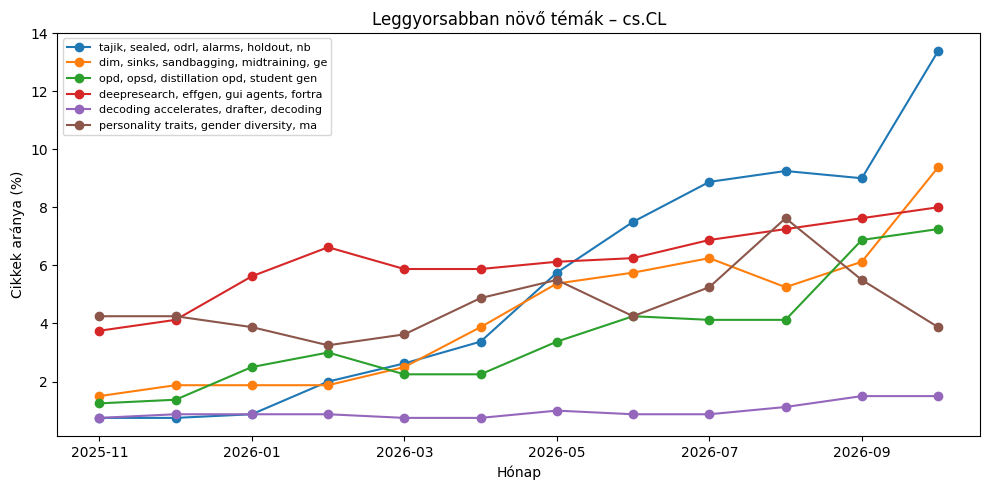

In [ ]:
import matplotlib.pyplot as plt
texts = (df.title + ". " + df.abstract).values
df["topic"], keywords = find_topics(emb, texts)
share, growth = topic_trends(df.month, df.topic)

trend_table = pd.DataFrame({"kulcsszavak": [keywords[t] for t in growth.index],
                            "cikkek": [int((df.topic == t).sum()) for t in growth.index],
                            "növekedés": growth.round(2).values}, index=growth.index)
trend_table.to_csv(f"{DATA_DIR}/trendek.csv")
display(trend_table.head(8))

top = growth.index[:6]
ax = (share[top] * 100).rolling(2, min_periods=1).mean().plot(figsize=(10, 5), marker="o")
ax.legend([keywords[t][:40] for t in top], fontsize=8, loc="upper left")
ax.set_ylabel("Cikkek aránya (%)"); ax.set_xlabel("Hónap"); ax.set_title(f"Leggyorsabban növő témák – {CATEGORY}")
plt.tight_layout(); plt.savefig(f"{DATA_DIR}/trendek.png", dpi=150); plt.show()

In [ ]:
# A nyelvi modell nevet ad a témáknak és rövid trendösszefoglalót ír (ez is a dokumentáció része: prompt + kimenet)
SUMMARY_PROMPT = """Az alábbi témák a(z) {cat} arXiv-kategóriában az utóbbi hónapokban a leggyorsabban növekvők.
Minden témához adj egy 2-5 szavas magyar nevet, és 1-2 mondatban írd le, miről szól, a példacikkek alapján.
A végén 3 mondatban foglald össze, merre tart a terület.

{topics}"""

blocks = []
for t in growth.index[:6]:
    examples = df[df.topic == t].sort_values("published", ascending=False).head(4)
    titles = "\n".join(f"  - {x.title} [{x.id}]" for x in examples.itertuples())
    blocks.append(f"Téma {t} (növekedés {growth[t]:.1f}x) – kulcsszavak: {keywords[t]}\n{titles}")
trend_summary = llm.models.generate_content(model=LLM_MODEL,
                    contents=SUMMARY_PROMPT.format(cat=CATEGORY, topics="\n\n".join(blocks))).text
print(trend_summary)

Íme az elemzés a megadott arXiv-kategória leggyorsabban növekvő témáiról:

**Téma 4**
* **Név:** Ügynökrendszerek megbízhatósága és igazgatása
* **Leírás:** Ez a terület az autonóm LLM-ügynökök döntéshozatali mechanizmusainak, tartalomlehívási hibáinak és demográfiai torzításainak naplózásával és auditálásával foglalkozik. A kutatások célja a rendszerek biztonságának, jogi és etikai megfelelésének nöpezlése strukturált korlátok és bizonyítékok alapján.

**Téma 1**
* **Név:** Nyelvi modellek belső dinamikája és önfejlesztése
* **Leírás:** A cikkek a modellek utótanítási fázisait, a jutalomhalászati (reward hacking) jelenségeket és az iteratív önfejlesztés közbeni konvergenciát vizsgálják. Kiemelten kutatják, hogyan módosítják a modellek önmagukat, és miként fedezhetők fel rejtett feladatszakértők a neurális hálózatokban.

**Téma 16**
* **Név:** Irányított tudásdisztilláció és prompt-optimalizálás
* **Leírás:** Ez a téma a kisebb modellek hatékonyságának növelésére fókuszál fejlett tudás

## 6. Kiértékelés

Töltsétek fel a listát 15–20 kérdéssel. Az `expected` mezőbe azoknak a cikkeknek az azonosítója kerül, amelyeknek
a találatok között kell lenniük (a `retrieve()` és a `df` böngészésével lehet megkeresni őket).

In [ ]:
def hit_at_k(results, expected, k):
    """1, ha a várt cikkek közül legalább egy benne van az első k találatban."""
    return int(bool(set(results[:k]) & set(expected)))

def evaluate(questions, k=TOP_K):
    rows = []
    for q in questions:
        ids = retrieve(q["q"], k=10).id.tolist()
        rows.append({"kérdés": q["q"], "hit@1": hit_at_k(ids, q["expected"], 1),
                     "hit@5": hit_at_k(ids, q["expected"], 5), "hit@10": hit_at_k(ids, q["expected"], 10)})
    res = pd.DataFrame(rows)
    return res, res[["hit@1", "hit@5", "hit@10"]].mean().round(2)

In [ ]:
EVAL_QUESTIONS = [
    # {"q": "Hogyan lehet csökkenteni a hallucinációt RAG-rendszerekben?", "expected": ["2503.01234"]},
]
if EVAL_QUESTIONS:
    eval_df, summary = evaluate(EVAL_QUESTIONS)
    eval_df.to_csv(f"{DATA_DIR}/eval.csv", index=False)
    display(eval_df); print(summary)

In [ ]:
# Kérdés–válasz napló mentése a dokumentációhoz (a kézi 1-5 pontozást ebbe a táblába lehet beírni)
pd.DataFrame(log).to_csv(f"{DATA_DIR}/qa_naplo.csv", index=False)
print(len(log), "válasz mentve")

2 válasz mentve
